# 01 - Exploratory Data Analysis: Give Me Some Credit (150k borrowers)

**Goal:** understand the data *before* modelling: default rate, missing values, data-quality traps, and which variables drive default.

**Dataset:** Give Me Some Credit (public, OpenML id 46929). Target `FinancialDistressNextTwoYears` = borrower had a 90+ days-past-due event within two years (our definition of *default*).

In [1]:
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.3})
FIG=Path("../reports/figures"); FIG.mkdir(parents=True,exist_ok=True)
df=pd.read_csv("../data/raw_gmsc.csv")
df["default"]=(df["FinancialDistressNextTwoYears"]=="Yes").astype(int)
df=df.drop(columns="FinancialDistressNextTwoYears")
print(df.shape); df.head()

(150000, 11)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,default
0,0.029690,57,0,0.283244,10121.0,7,0,1,0,0.0,0
1,0.000000,57,0,0.142562,7750.0,9,0,1,0,0.0,0
2,0.036569,48,0,0.236294,6000.0,6,0,2,0,3.0,0
3,1.018331,41,0,0.163138,4958.0,4,0,0,0,0.0,0
4,1.008799,49,0,3942.000000,NaN,10,0,1,0,0.0,0


## 1. Default rate (class balance)

Default rate: 6.68%  (10,026 of 150,000)
A model that predicts 'nobody defaults' is 93.32% accurate and completely useless -> we judge with AUC/Gini/KS, not accuracy.


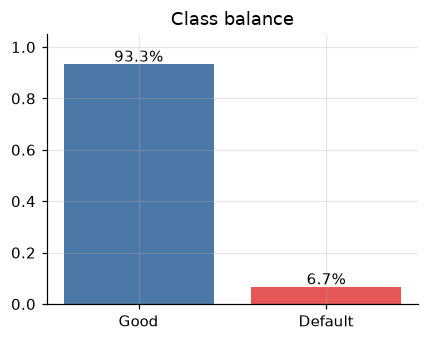

In [2]:
rate=df["default"].mean(); print(f"Default rate: {rate:.2%}  ({df['default'].sum():,} of {len(df):,})")
print(f"A model that predicts 'nobody defaults' is {1-rate:.2%} accurate and completely useless -> we judge with AUC/Gini/KS, not accuracy.")
fig,ax=plt.subplots(figsize=(4,3.2)); ax.bar(["Good","Default"],[1-rate,rate],color=["#4C78A8","#E45756"])
for i,v in enumerate([1-rate,rate]): ax.text(i,v+.01,f"{v:.1%}",ha="center")
ax.set_ylim(0,1.05); ax.set_title("Class balance"); fig.tight_layout(); fig.savefig(FIG/"eda_class_balance.png"); plt.show()

## 2. Missing values and duplicates

In [3]:
miss=df.isna().sum().to_frame("missing"); miss["pct"]=(miss.missing/len(df)*100).round(2); print(miss[miss.missing>0])
print("\nDuplicate rows:",df.duplicated().sum())
print("\nDefault rate when MonthlyIncome missing vs present:")
print(df.groupby(df.MonthlyIncome.isna())["default"].mean().rename({False:"present",True:"missing"}).round(4))
print("\nDefault rate when NumberOfDependents missing vs present:")
print(df.groupby(df.NumberOfDependents.isna())["default"].mean().rename({False:"present",True:"missing"}).round(4))

                    missing    pct
MonthlyIncome         29731  19.82
NumberOfDependents     3924   2.62

Duplicate rows: 609

Default rate when MonthlyIncome missing vs present:
MonthlyIncome
present    0.0695
missing    0.0561
Name: default, dtype: float64

Default rate when NumberOfDependents missing vs present:


NumberOfDependents
present    0.0674
missing    0.0456
Name: default, dtype: float64


## 3. Data-quality traps

In [4]:
late=["NumberOfTime30-59DaysPastDueNotWorse","NumberOfTime60-89DaysPastDueNotWorse","NumberOfTimes90DaysLate"]
for c in late: print(c, "-> rows with value >= 96:", (df[c]>=96).sum(), "| values:", sorted(df.loc[df[c]>=96,c].unique()))
code_rows=(df[late]>=96).any(axis=1)
print(f"\nRows carrying the 96/98 code: {code_rows.sum()}  default rate = {df.loc[code_rows,'default'].mean():.1%}  (vs {df.loc[~code_rows,'default'].mean():.1%} for everyone else)")
print("Age < 18:", (df.age<18).sum(), "| Age distribution min/max:", df.age.min(), df.age.max())
print("RevolvingUtilization > 1:", f"{(df.RevolvingUtilizationOfUnsecuredLines>1).mean():.2%}", "| > 10:", (df.RevolvingUtilizationOfUnsecuredLines>10).sum(), "| max:", df.RevolvingUtilizationOfUnsecuredLines.max())
print("DebtRatio > 1:", f"{(df.DebtRatio>1).mean():.2%}", "| max:", df.DebtRatio.max())
print("MonthlyIncome == 0:", (df.MonthlyIncome==0).sum(), "| max:", df.MonthlyIncome.max())

NumberOfTime30-59DaysPastDueNotWorse -> rows with value >= 96: 269 | values: [np.int64(96), np.int64(98)]
NumberOfTime60-89DaysPastDueNotWorse -> rows with value >= 96: 269 | values: [np.int64(96), np.int64(98)]
NumberOfTimes90DaysLate -> rows with value >= 96: 269 | values: [np.int64(96), np.int64(98)]



Rows carrying the 96/98 code: 269  default rate = 54.6%  (vs 6.6% for everyone else)
Age < 18: 1 | Age distribution min/max: 0 109
RevolvingUtilization > 1: 2.21% | > 10: 241 | max: 50708.0
DebtRatio > 1: 23.42% | max: 329664.0
MonthlyIncome == 0: 1634 | max: 3008750.0


## 4. Default rate by driver

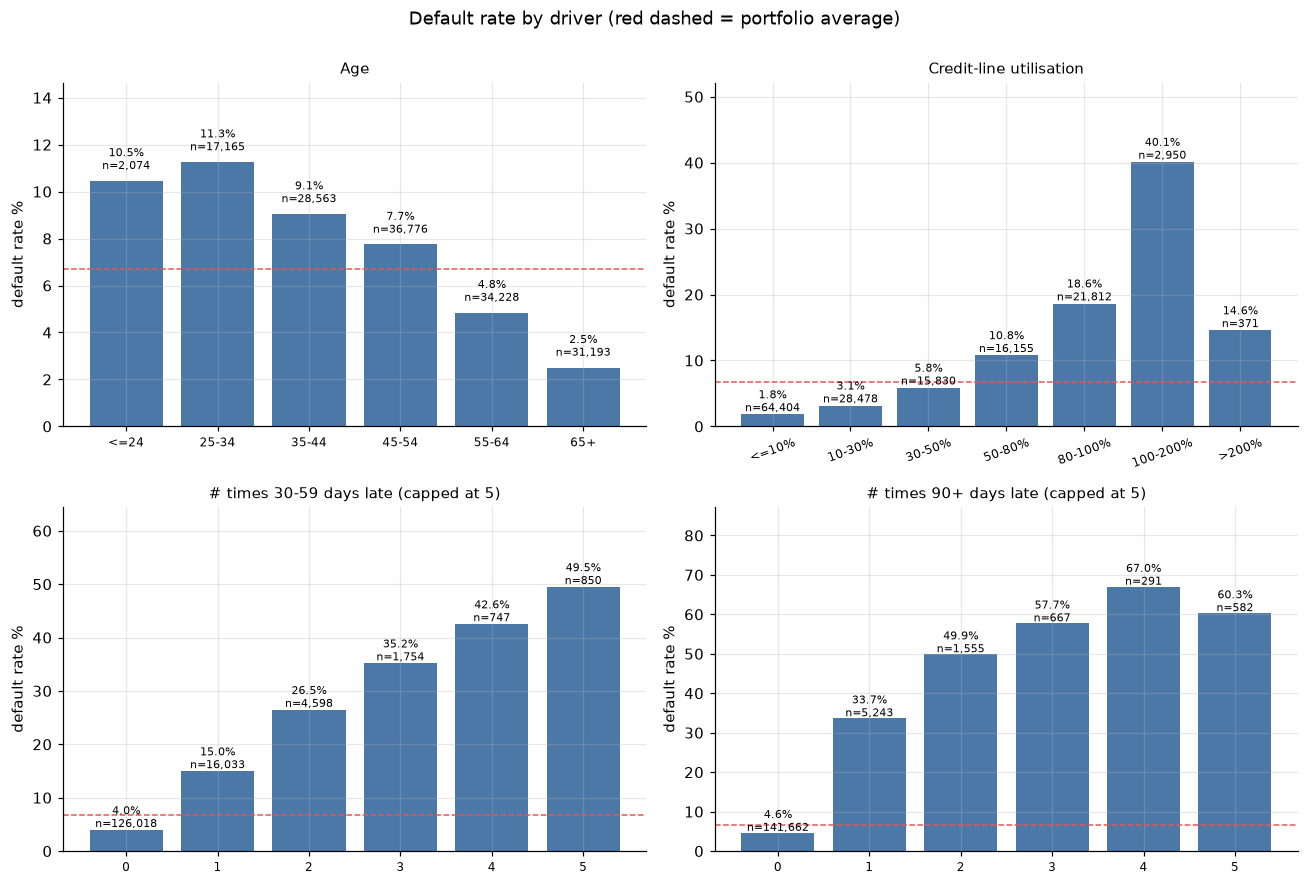

In [5]:
def rate_plot(ax,s,title,bins=None,labels=None,rot=0):
    g=s if bins is None else pd.cut(s,bins,labels=labels)
    t=df.groupby(g,observed=True)["default"].agg(["mean","size"])
    ax.bar(t.index.astype(str),t["mean"]*100,color="#4C78A8")
    for i,(m,n) in enumerate(zip(t["mean"],t["size"])): ax.text(i,m*100+.5,f"{m:.1%}\nn={n:,}",ha="center",fontsize=7)
    ax.axhline(rate*100,color="#E45756",ls="--",lw=1); ax.set_title(title,fontsize=10); ax.set_ylabel("default rate %"); ax.tick_params(axis="x",rotation=rot,labelsize=8)
    ax.set_ylim(0,max(t["mean"]*100)*1.3)
fig,axs=plt.subplots(2,2,figsize=(12,8))
rate_plot(axs[0,0],df.age,"Age",[0,24,34,44,54,64,120],["<=24","25-34","35-44","45-54","55-64","65+"])
rate_plot(axs[0,1],df.RevolvingUtilizationOfUnsecuredLines,"Credit-line utilisation",[-.01,.1,.3,.5,.8,1,2,1e6],["<=10%","10-30%","30-50%","50-80%","80-100%","100-200%",">200%"],rot=20)
rate_plot(axs[1,0],df["NumberOfTime30-59DaysPastDueNotWorse"].clip(upper=5),"# times 30-59 days late (capped at 5)")
rate_plot(axs[1,1],df["NumberOfTimes90DaysLate"].clip(upper=5),"# times 90+ days late (capped at 5)")
fig.suptitle("Default rate by driver (red dashed = portfolio average)",y=1.0); fig.tight_layout(); fig.savefig(FIG/"eda_drivers.png"); plt.show()

Default rate by income quintile (low -> high):
MonthlyIncome
(-0.001, 3000.0]       9.08
(3000.0, 4544.2]       8.60
(4544.2, 6300.0]       7.01
(6300.0, 9083.0]       5.53
(9083.0, 3008750.0]    4.50


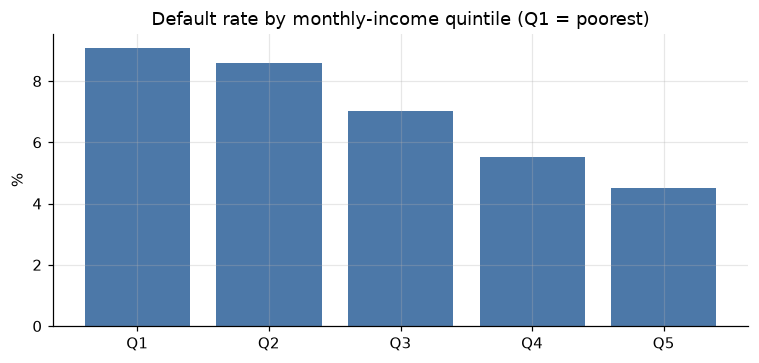

In [6]:
inc=df.MonthlyIncome.where(df.MonthlyIncome<=df.MonthlyIncome.quantile(.99))
t=df.groupby(pd.qcut(df.MonthlyIncome,5,duplicates="drop"),observed=True)["default"].mean()
print("Default rate by income quintile (low -> high):"); print((t*100).round(2).to_string())
fig,ax=plt.subplots(figsize=(7,3.4)); ax.bar([f"Q{i+1}" for i in range(len(t))],t.values*100,color="#4C78A8"); ax.set_title("Default rate by monthly-income quintile (Q1 = poorest)"); ax.set_ylabel("%"); fig.tight_layout(); fig.savefig(FIG/"eda_income.png"); plt.show()

## 5. Why raw correlation is misleading here

In [7]:
corr=df.corr(numeric_only=True)["default"].drop("default").sort_values()
print(corr.round(3).to_string())
print("\nUtilisation looks uncorrelated (~0) only because of a handful of absurd outliers (max = 50,708). Binned, it is one of the strongest drivers (1.8% -> 40%). This is exactly why we use WoE binning: it is robust to outliers and captures non-linear shape.")
print("Spearman (rank) correlation of utilisation with default:", round(df["RevolvingUtilizationOfUnsecuredLines"].corr(df["default"],method="spearman"),3))

age                                    -0.115
NumberOfOpenCreditLinesAndLoans        -0.030
MonthlyIncome                          -0.020
DebtRatio                              -0.008
NumberRealEstateLoansOrLines           -0.007
RevolvingUtilizationOfUnsecuredLines   -0.002
NumberOfDependents                      0.046
NumberOfTime60-89DaysPastDueNotWorse    0.102
NumberOfTimes90DaysLate                 0.117
NumberOfTime30-59DaysPastDueNotWorse    0.126

Utilisation looks uncorrelated (~0) only because of a handful of absurd outliers (max = 50,708). Binned, it is one of the strongest drivers (1.8% -> 40%). This is exactly why we use WoE binning: it is robust to outliers and captures non-linear shape.


Spearman (rank) correlation of utilisation with default: 0.24


## 6. Five plain-English findings

1. **Defaults are rare (6.7%).** Predicting "no one defaults" is 93.3% accurate and worthless, so we evaluate with AUC / Gini / KS, never accuracy.
2. **Past delinquency is the strongest signal.** Borrowers with zero 90+ day lates default at 4.6%; with one, 33.7%; with three, 57.7%. Past behaviour predicts future behaviour.
3. **Utilisation is a strong but non-linear driver, hidden by outliers.** Default climbs from 1.8% (<=10% utilisation) to 18.6% (80-100%) and 40.1% (100-200%). Raw correlation shows ~0 because of absurd outliers, so we need binning (WoE), not raw values.
4. **Younger and lower-income borrowers are riskier.** Default falls from ~11% (age 25-34) to 2.5% (65+), and from 9.1% (lowest income quintile) to 4.5% (highest).
5. **The data has traps we must fix before modelling.** (a) 269 rows hold the placeholder codes 96/98 in the late-payment columns and default at 54.6%; these are not real counts and must be flagged and neutralised, (b) 20% of MonthlyIncome and 2.6% of dependents are missing (income-missing borrowers actually default slightly *less*, 5.6% vs 7.0%, so missingness itself is informative and gets a flag), (c) one borrower aged 0 and extreme outliers in utilisation, DebtRatio and income. Also, 609 rows are exact duplicates, but they are mostly thin-file borrowers with identical all-zero profiles (85% have missing income), so they are different people, not errors. We keep them. Finally, when income is missing DebtRatio is a raw dollar amount (median 1,159), not a ratio, so it must be treated as unknown.

**Next step:** `src/features.py` cleans these issues and builds engineered features.